# 01 · How big is the superfamily compared to its name?
**Question.** The "ABHD" gene names cover only part of the α/β-hydrolase superfamily. How much?
**Inputs.** UniProt entries (`data/raw/uniprot`), CATH FunFams from Christina (`data/raw/christina`).

In [1]:
import sys, warnings; warnings.filterwarnings("ignore")
from pathlib import Path; sys.path.insert(0, str(Path.cwd().parent / "src"))   # notebooks/ -> ../src
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from abhd import config as C, data as D, plots as P
pd.set_option("display.width", 160, "display.max_colwidth", 60)
meta = D.load_entries()

## UniProt entries

In [2]:
print(f"{len(meta)} human UniProt entries in the 'ab hydrolase superfamily' (incl. isoform/fragment entries)")
print(f"  reviewed (Swiss-Prot): {meta.reviewed.sum()}   ABHD-named: {meta.abhd_named.sum()}   "
      f"reviewed and ABHD-named: {(meta.abhd_named & meta.reviewed).sum()}")
print(f"  distinct gene names: {meta.gene_name.replace('', np.nan).nunique()}")

210 human UniProt entries in the 'ab hydrolase superfamily' (incl. isoform/fragment entries)
  reviewed (Swiss-Prot): 51   ABHD-named: 36   reviewed and ABHD-named: 16
  distinct gene names: 57


## FunFams
Each FunFam (CATH functional family) in superfamily 3.40.50.1820 that contains human sequences is one row.
A FunFam is "ABHD-named" if any human member has an `ABHD*` gene name.

In [3]:
ff, ev = D.load_funfam()
genes = [g for s in ff.human_genes for g in s.split(";")]
print(f"{len(ff)} FunFams, {len(genes)} human genes, of which {sum(g.startswith('ABHD') for g in genes)} are ABHD-named")
print(f"FunFams containing an ABHD-named gene: {ff.has_abhd_named.sum()} / {len(ff)}")
print(f"FunFams with a single human member: {(ff.n_human_uniprots == 1).sum()}")
ff[["funfam_id", "human_genes", "has_abhd_named"]].reset_index(drop=True).head(80)

76 FunFams, 107 human genes, of which 17 are ABHD-named
FunFams containing an ABHD-named gene: 15 / 76
FunFams with a single human member: 61


,funfam_id,human_genes,has_abhd_named
0,3.40.50.1820-FF-000001,NLGN4X;NLGN1;NLGN4Y;NLGN2;NLGN3,False
1,3.40.50.1820-FF-000002,ESD,False
2,3.40.50.1820-FF-000003,DPP4;DPP6;FAP;DPP10,False
3,3.40.50.1820-FF-000005,PREP,False
4,3.40.50.1820-FF-000006,NDRG1;NDRG3,False
...,...,...,...
71,3.40.50.1820-FF-000183,LCAT,False
72,3.40.50.1820-FF-000187,LCAT,False
73,3.40.50.1820-FF-000199,LIPE,False
74,3.40.50.1820-FF-000269,ACOT6,False


**Reading this.** Most FunFams contain no ABHD-named gene at all (neuroligins, DPP4/FAP, carboxylesterases, lipases,
cholinesterases, NDRGs, epoxide hydrolases…). The ABHD naming reflects when a gene was characterised, not where it sits in the fold.

## Similarity between FunFams
`human_abhd_funfam_hhalign_matrix.csv` holds HHalign E-values between FunFam HMMs (0 on the diagonal; smaller = more similar).
For clustering these are turned into a distance: symmetrise (best of the two directions), take −log10(E), clip at 0, flip.
(The original notebook passed raw E-values to `linkage`; that is not a metric.)

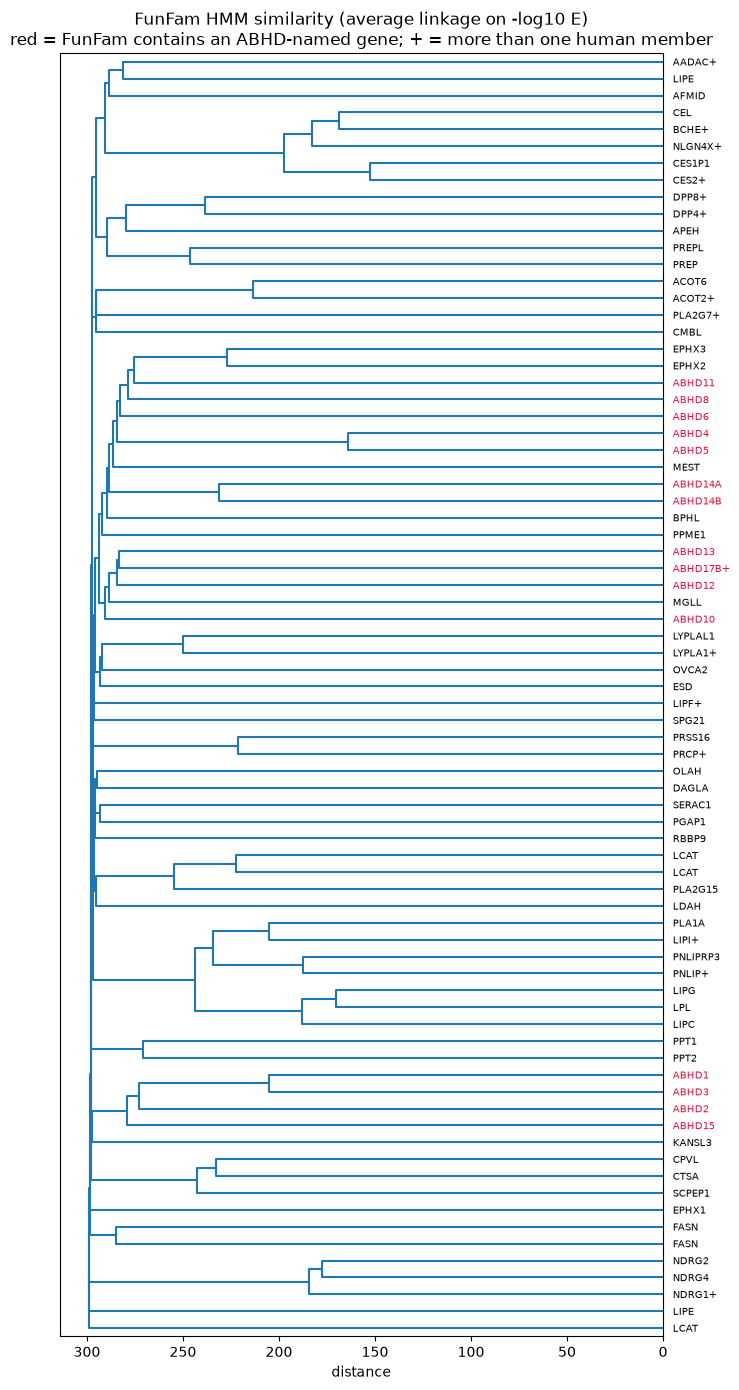

In [4]:
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform
dist = D.evalue_to_distance(ev)
Z = linkage(squareform(dist.values, checks=False), method="average")
labels = [f"{r.human_genes.split(';')[0]}{'+' if r.n_human_uniprots > 1 else ''}" for r in ff.loc[dist.index].itertuples()]
colour = ff.loc[dist.index, "has_abhd_named"].values
fig, ax = plt.subplots(figsize=(7, 14))
d = dendrogram(Z, labels=labels, orientation="left", ax=ax, leaf_font_size=7, color_threshold=0)
for t, leaf in zip(ax.get_ymajorticklabels(), d["leaves"]):   # leaf = row index in the matrix
    t.set_color("crimson" if colour[leaf] else "black")
ax.set(title="FunFam HMM similarity (average linkage on -log10 E)\nred = FunFam contains an ABHD-named gene; + = more than one human member",
       xlabel="distance")
plt.tight_layout(); plt.show()

**Reading this.** Distances saturate near the maximum (E-values clipped at 1e-300 give ≈ 300): most FunFam pairs have no detectable
HMM similarity, so only the lowest branches carry information. ABHD-named FunFams (red) sit in several unrelated places, interleaved
with non-ABHD ones (e.g. ABHD14A/B beside EPHX2/3, ABHD1/2/3/15 as their own group).

## Nearest FunFams to the ABHD2 and ABHD14B FunFams (HHalign E-value)

In [5]:
def ff_neighbours(gene, n=5):
    fid = ff.index[ff.human_genes.str.split(";").apply(lambda g: gene in g)][0]
    s = ev[fid].drop(fid).sort_values().head(n)
    return pd.DataFrame({"funfam": s.index, "genes": ff.loc[s.index, "human_genes"].values, "E-value": s.values})
for g in ["ABHD2", "ABHD14B"]:
    print(g); display(ff_neighbours(g))

ABHD2


,funfam,genes,E-value
0,3.40.50.1820-FF-000079,ABHD3,9.700000e-33
1,3.40.50.1820-FF-000167,ABHD1,1.500000e-22
2,3.40.50.1820-FF-000103,ABHD15,1.600000e-11
3,3.40.50.1820-FF-000017,ABHD8,1.700000e-05
4,3.40.50.1820-FF-000068,LDAH,2.200000e-05


ABHD14B


,funfam,genes,E-value
0,3.40.50.1820-FF-000093,ABHD14A,2.600000e-69
1,3.40.50.1820-FF-000161,EPHX3,2.300000e-22
2,3.40.50.1820-FF-000039,ABHD11,6.600000e-19
3,3.40.50.1820-FF-000067,EPHX2,4.300000e-18
4,3.40.50.1820-FF-000082,ABHD6,2.700000e-14


**Reading this.** ABHD14B has an obvious close relative (ABHD14A, E ≈ 1e-69) and then a clear drop (EPHX3 ≈ 1e-22). ABHD2's
nearest FunFam is ABHD3 (≈ 1e-33), then ABHD1 (≈ 1e-22). Beyond the top 2–3 the E-values fall off quickly, so FunFam-level
neighbours past that point are weak evidence of relatedness.